In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import pandas as pd

path = r"C:\Users\jatin\Downloads\Banking Dataset\indian_banking_transactions.csv"

df = pd.read_csv(path)

# Display first 5 rows
df.head()

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,Maharashtra,764,0,NaN,0.00,Success,Branch,Verified,0,15
1,TXN000000002,CUST000861,2019-01-01,03:00,Current,UPI,392.67,Credit,14451.14,Education,West Bengal,630,0,NaN,0.00,Success,Mobile_App,Verified,0,3
2,TXN000000003,CUST076821,2019-01-01,18:03,Fixed Deposit,POS,1255.97,Debit,47621.87,Utilities,Punjab,813,1,Home,1433.91,Success,Mobile_App,Verified,0,18
3,TXN000000004,CUST054887,2019-01-01,08:03,Savings,UPI,2580.68,Debit,34467.85,Travel,Karnataka,628,1,Personal,6280.35,Success,API,Verified,0,8
4,TXN000000005,CUST006266,2019-01-01,14:23,Fixed Deposit,UPI,2573.80,Debit,26617.40,Utilities,West Bengal,767,0,NaN,0.00,Success,API,Verified,0,14


In [3]:
#informqtion about the columns
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550000 entries, 0 to 549999
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   transaction_id         550000 non-null  object 
 1   customer_id            550000 non-null  object 
 2   transaction_date       550000 non-null  object 
 3   transaction_time       550000 non-null  object 
 4   account_type           550000 non-null  object 
 5   transaction_type       550000 non-null  object 
 6   transaction_amount     550000 non-null  float64
 7   transaction_direction  550000 non-null  object 
 8   account_balance        550000 non-null  float64
 9   merchant_category      550000 non-null  object 
 10  state                  550000 non-null  object 
 11  credit_score           550000 non-null  int64  
 12  has_loan               550000 non-null  int64  
 13  loan_type              172866 non-null  object 
 14  emi_amount             550000 non-nu

In [4]:
#Describe every row and column
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,550000,550000,TXN000000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,550000,79916,CUST003688,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_date,550000,1827,2023-11-11,373,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_time,550000,1440,06:25,448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
account_type,550000,5,Savings,219651,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_type,550000,10,UPI,153986,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_amount,550000.0,NaN,NaN,NaN,29907.093934,139610.09652,2.4,763.0375,2035.735,8557.4975,10000000.0
transaction_direction,550000,2,Debit,370394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
account_balance,550000.0,NaN,NaN,NaN,84550.115076,170914.586239,500.0,15157.785,36422.87,87607.035,5000000.0
merchant_category,550000,15,Retail,66180,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# checking the null values
print(df.isnull().sum())

transaction_id                0
customer_id                   0
transaction_date              0
transaction_time              0
account_type                  0
transaction_type              0
transaction_amount            0
transaction_direction         0
account_balance               0
merchant_category             0
state                         0
credit_score                  0
has_loan                      0
loan_type                377134
emi_amount                    0
transaction_status            0
channel                       0
kyc_status                    0
is_fraud                      0
transaction_hour              0
dtype: int64


In [6]:
#duplicate values
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
#number of fraud
print(df["is_fraud"].value_counts(dropna=False))

is_fraud
0    545127
1      4873
Name: count, dtype: int64


In [8]:
# Number rows and columns
print("Shape:", df.shape)

Shape: (550000, 20)


In [9]:
print(df.columns.tolist())
#columns are already in correct form

['transaction_id', 'customer_id', 'transaction_date', 'transaction_time', 'account_type', 'transaction_type', 'transaction_amount', 'transaction_direction', 'account_balance', 'merchant_category', 'state', 'credit_score', 'has_loan', 'loan_type', 'emi_amount', 'transaction_status', 'channel', 'kyc_status', 'is_fraud', 'transaction_hour']


In [10]:
#number of unique vqlue holds each columns
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

transaction_id: 550000 unique values
customer_id: 79916 unique values
transaction_date: 1827 unique values
transaction_time: 1440 unique values
account_type: 5 unique values
transaction_type: 10 unique values
transaction_amount: 374552 unique values
transaction_direction: 2 unique values
account_balance: 536170 unique values
merchant_category: 15 unique values
state: 10 unique values
credit_score: 600 unique values
has_loan: 2 unique values
loan_type: 6 unique values
emi_amount: 177524 unique values
transaction_status: 4 unique values
channel: 6 unique values
kyc_status: 3 unique values
is_fraud: 2 unique values
transaction_hour: 24 unique values


In [11]:
#The following code helps to identify likely matching columns:
for col in df.columns:
    if any(word in col for word in ["fraud", "amount", "date", "time", "payment", "channel", "state"]):
        print(col, df[col].dropna().unique()[:10])

transaction_date ['2019-01-01' '2019-01-02' '2019-01-03' '2019-01-04' '2019-01-05'
 '2019-01-06' '2019-01-07' '2019-01-08' '2019-01-09' '2019-01-10']
transaction_time ['15:28' '03:00' '18:03' '08:03' '14:23' '01:51' '06:27' '23:40' '20:25'
 '22:15']
transaction_amount [ 1820.17   392.67  1255.97  2580.68  2573.8  39172.48  4008.09 17797.85
  3284.62   921.64]
state ['Maharashtra' 'West Bengal' 'Punjab' 'Karnataka' 'Tamil Nadu' 'Telangana'
 'Delhi' 'UP' 'Rajasthan' 'Gujarat']
emi_amount [    0.    1433.91  6280.35  4197.37  4251.79  9630.13  5845.85  9645.1
 20598.86 12565.3 ]
channel ['Branch' 'Mobile_App' 'API' 'Web' 'ATM' 'POS_Terminal']
is_fraud [0 1]


In [12]:
# converting date time to datetime data type in Pandas
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"],
    errors="coerce"
)

In [13]:
#converts the transaction_amount column into a numeric data type
df["transaction_amount"] = pd.to_numeric(
    df["transaction_amount"],
    errors="coerce"
)

In [14]:
# A NaN value in loan_type does not automatically mean the customer has no loan. Analysis of loan_type to fill missing values
missing_loan = df[df["loan_type"].isna()]

missing_loan.head(10)

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,Maharashtra,764,0,NaN,0.0,Success,Branch,Verified,0,15
1,TXN000000002,CUST000861,2019-01-01,03:00,Current,UPI,392.67,Credit,14451.14,Education,West Bengal,630,0,NaN,0.0,Success,Mobile_App,Verified,0,3
4,TXN000000005,CUST006266,2019-01-01,14:23,Fixed Deposit,UPI,2573.80,Debit,26617.40,Utilities,West Bengal,767,0,NaN,0.0,Success,API,Verified,0,14
7,TXN000000008,CUST060264,2019-01-01,23:40,Current,Net_Banking,17797.85,Debit,17568.23,Healthcare,Punjab,651,0,NaN,0.0,Success,Mobile_App,Expired,0,23
8,TXN000000009,CUST016024,2019-01-01,20:25,Salary,Credit_Card,3284.62,Debit,66973.00,Food & Dining,Tamil Nadu,443,0,NaN,0.0,Success,Web,Verified,0,20
10,TXN000000011,CUST067222,2019-01-01,08:50,Salary,Cheque,95223.86,Debit,200239.14,Government,Maharashtra,358,0,NaN,0.0,Success,Mobile_App,Verified,0,8
11,TXN000000012,CUST064821,2019-01-01,13:52,Current,ATM_Withdrawal,1000.00,Debit,32673.88,E-Commerce,Tamil Nadu,500,0,NaN,0.0,Failed,Mobile_App,Verified,0,13
13,TXN000000014,CUST059736,2019-01-01,20:17,NRI,ATM_Withdrawal,2000.00,Debit,100172.21,E-Commerce,Telangana,843,0,NaN,0.0,Success,ATM,Verified,0,20
14,TXN000000015,CUST062956,2019-01-01,15:31,NRI,POS,233.62,Debit,638972.89,Government,Telangana,511,0,NaN,0.0,Failed,Mobile_App,Verified,0,15
15,TXN000000016,CUST064926,2019-01-01,18:11,Fixed Deposit,POS,1251.80,Debit,13200.07,Government,Delhi,794,0,NaN,0.0,Success,Mobile_App,Verified,0,18


In [20]:
(df['has_loan'] == True).sum()

np.int64(192288)

In [22]:
(df['has_loan'] == False).sum()

np.int64(357712)

In [48]:
df.loc[
    (df['has_loan'] == False) & (df['loan_type'].isna()),
    'loan_type'
] = 'No Loan'


In [49]:
loan_missing_type = df[
    (df['has_loan'] == True) &
    (df['loan_type'].isna())
]

print(loan_missing_type)

       transaction_id customer_id transaction_date transaction_time  \
40       TXN000000041  CUST023898       2019-01-01            11:35   
41       TXN000000042  CUST068149       2019-01-01            20:07   
68       TXN000000069  CUST009269       2019-01-01            19:00   
72       TXN000000073  CUST008572       2019-01-01            07:12   
109      TXN000000110  CUST052993       2019-01-01            14:02   
...               ...         ...              ...              ...   
549871   TXN000549872  CUST062548       2024-01-01            14:10   
549879   TXN000549880  CUST001080       2024-01-01            03:18   
549889   TXN000549890  CUST065835       2024-01-01            23:31   
549946   TXN000549947  CUST019060       2024-01-01            02:01   
549982   TXN000549983  CUST073091       2024-01-01            20:18   

       account_type transaction_type  transaction_amount  \
40          Savings       Auto_Debit              879.10   
41           Salary        

In [50]:
print("Count:", len(loan_missing_type))

Count: 19422


In [51]:
loan_missing_type = df.loc[
    (df['has_loan'] == True) &
    (df['loan_type'].isna())
]

loan_missing_type[
    ['customer_id', 'has_loan', 'loan_type', 'emi_amount']
].head(20)


,customer_id,has_loan,loan_type,emi_amount
40,CUST023898,1,NaN,8597.49
41,CUST068149,1,NaN,6697.80
68,CUST009269,1,NaN,5683.47
72,CUST008572,1,NaN,8317.18
109,CUST052993,1,NaN,6982.45
149,CUST021960,1,NaN,4558.20
193,CUST072083,1,NaN,10510.49
238,CUST038361,1,NaN,3790.34
256,CUST040819,1,NaN,4139.92
316,CUST054749,1,NaN,2268.92


In [52]:
print("Customers/records with missing loan type:",
      len(loan_missing_type))

print("Unique customers affected:",
      loan_missing_type['customer_id'].nunique())

Customers/records with missing loan type: 19422
Unique customers affected: 17241


In [53]:
customer_counts = (
    loan_missing_type['customer_id']
    .value_counts()
)

customer_counts[customer_counts > 1]

customer_id
CUST055590    4
CUST042146    4
CUST008759    4
CUST056573    4
CUST028618    4
             ..
CUST068324    2
CUST020783    2
CUST071242    2
CUST029073    2
CUST001691    2
Name: count, Length: 2010, dtype: int64

In [54]:
customer_counts.head(10)

customer_id
CUST055590    4
CUST042146    4
CUST008759    4
CUST056573    4
CUST028618    4
CUST006273    4
CUST001436    4
CUST076746    4
CUST068912    4
CUST014807    4
Name: count, dtype: int64

In [55]:
df[
    df['customer_id'].isin(
        customer_counts[customer_counts > 1].index
    ) &
    (df['has_loan'] == True) &
    (df['loan_type'].isna())
].sort_values('customer_id').head(20)

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
368755,TXN000368756,CUST000021,2022-05-10,16:55,Current,NEFT,5391.96,Debit,41370.19,Food & Dining,Tamil Nadu,320,1,NaN,6493.29,Success,Mobile_App,Verified,0,16
202850,TXN000202851,CUST000021,2020-11-05,16:58,Savings,RTGS,183743.34,Debit,38132.44,E-Commerce,Delhi,624,1,NaN,3038.88,Success,ATM,Verified,0,16
372063,TXN000372064,CUST000027,2022-05-21,01:18,Current,POS,1731.59,Debit,9880.42,Travel,Gujarat,741,1,NaN,3582.33,Success,Web,Verified,0,1
436663,TXN000436664,CUST000027,2022-12-20,14:05,Savings,UPI,359.14,Debit,63071.97,Government,Tamil Nadu,611,1,NaN,2947.89,Success,Mobile_App,Verified,0,14
520429,TXN000520430,CUST000111,2023-09-25,10:51,Current,UPI,984.68,Credit,647146.16,Salary,Karnataka,567,1,NaN,2245.60,Success,POS_Terminal,Verified,0,10
322070,TXN000322071,CUST000111,2021-12-06,10:14,Salary,Credit_Card,3573.32,Debit,53158.74,Food & Dining,West Bengal,577,1,NaN,1498.17,Success,Mobile_App,Expired,0,10
532582,TXN000532583,CUST000117,2023-11-04,23:38,Savings,UPI,16706.88,Credit,133974.03,Salary,Tamil Nadu,492,1,NaN,1757.71,Success,Web,Verified,0,23
232923,TXN000232924,CUST000117,2021-02-12,12:19,Current,POS,1005.29,Debit,37417.71,Food & Dining,Karnataka,778,1,NaN,4679.34,Success,Mobile_App,Verified,0,12
20544,TXN000020545,CUST000155,2019-03-10,19:17,Fixed Deposit,Net_Banking,61329.01,Credit,8167.25,Peer Transfer,Delhi,634,1,NaN,6339.25,Success,Mobile_App,Verified,0,19
237809,TXN000237810,CUST000155,2021-03-01,13:11,Fixed Deposit,NEFT,2399.16,Credit,59657.74,Retail,Gujarat,526,1,NaN,5961.55,Success,Mobile_App,Verified,0,13


In [56]:
customer_loan_types = (
    df[df['has_loan'] == 1]
    .groupby('customer_id')['loan_type']
    .agg(lambda x: x.dropna().unique().tolist())
)

print(customer_loan_types.head(20))

customer_id
CUST000001                         [Home, Business]
CUST000002                                   [Auto]
CUST000003                                   [Home]
CUST000004                               [Personal]
CUST000005                                   [Home]
CUST000006    [Personal, Education, Auto, Business]
CUST000007                               [Personal]
CUST000008                    [Personal, Education]
CUST000009                         [Auto, Personal]
CUST000010                         [Personal, Auto]
CUST000011              [Personal, Gold, Education]
CUST000012                         [Auto, Business]
CUST000013                              [Education]
CUST000014                                   [Home]
CUST000015                   [Gold, Auto, Personal]
CUST000016                              [Education]
CUST000017                         [Auto, Business]
CUST000018                     [Personal, Business]
CUST000020                   [Personal, Auto, Home]


In [62]:
# Count distinct loan types for each customer
loan_type_count = customer_loan_types.apply(len)

# Customers with more than one distinct loan type
multiple_loan_customers = loan_type_count[loan_type_count > 1]

print("Customers with multiple loan types:",
      len(multiple_loan_customers))

print(multiple_loan_customers.head(20))

Customers with multiple loan types: 45735
customer_id
CUST000001    2
CUST000006    4
CUST000008    2
CUST000009    2
CUST000010    2
CUST000011    3
CUST000012    2
CUST000015    3
CUST000017    2
CUST000018    2
CUST000020    3
CUST000021    3
CUST000023    2
CUST000026    4
CUST000029    2
CUST000030    4
CUST000033    3
CUST000035    3
CUST000036    2
CUST000037    4
Name: loan_type, dtype: int64


In [64]:
print(
    customer_loan_types[
        customer_loan_types.apply(len) > 1
    ].sort_values(
        key=lambda x: x.apply(len),
        ascending=False
    ).head(20)
)

customer_id
CUST069631    [Education, Auto, Business, Home, Personal, Gold]
CUST028811    [Business, Auto, Gold, Personal, Home, Education]
CUST050201    [Business, Home, Auto, Education, Gold, Personal]
CUST022756    [Education, Home, Auto, Personal, Business, Gold]
CUST013199    [Education, Personal, Gold, Business, Auto, Home]
CUST016979    [Home, Education, Business, Auto, Gold, Personal]
CUST026577    [Auto, Business, Gold, Education, Personal, Home]
CUST037088    [Business, Auto, Gold, Education, Home, Personal]
CUST043411    [Business, Gold, Home, Auto, Personal, Education]
CUST075416    [Business, Education, Gold, Personal, Auto, Home]
CUST030870    [Personal, Business, Home, Education, Auto, Gold]
CUST022294    [Personal, Gold, Auto, Home, Business, Education]
CUST042081    [Home, Personal, Auto, Business, Gold, Education]
CUST062230    [Auto, Gold, Business, Personal, Home, Education]
CUST022857    [Personal, Education, Auto, Business, Home, Gold]
CUST022204    [Personal, Bus

In [65]:
# Customers with a loan but missing loan type
df.loc[
    (df['has_loan'] == 1) & (df['loan_type'].isna()),
    'loan_type'
] = 'Unknown'

In [66]:
loan_type_count = customer_loan_types.apply(len)

multiple_loan_customers = loan_type_count[loan_type_count > 1]

print("Customers with multiple loan types:",
      len(multiple_loan_customers))

Customers with multiple loan types: 45735


# EDA

In [70]:
fraud_counts = df["is_fraud"].value_counts(dropna=False)

fraud_percentages = (
    df["is_fraud"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

print("Fraud counts:")
print(fraud_counts)

print("\nFraud percentages:")
print(fraud_percentages)

Fraud counts:
is_fraud
0    545127
1      4873
Name: count, dtype: int64

Fraud percentages:
is_fraud
0    99.11
1     0.89
Name: proportion, dtype: float64


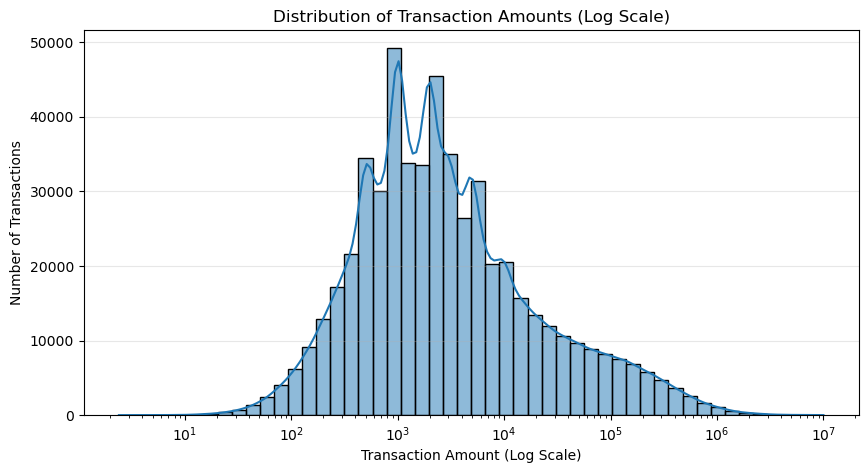

In [77]:
#Analyze transaction amounts
plt.figure(figsize=(10, 5))

# log_scale=True handles the distribution stretch automatically
sns.histplot(df['transaction_amount'], bins=50, log_scale=True, kde=True)

plt.title('Distribution of Transaction Amounts (Log Scale)')
plt.xlabel('Transaction Amount (Log Scale)')
plt.ylabel('Number of Transactions')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [74]:
#Analyze fraud by payment method
fraud_by_payment = (
    df.groupby("transaction_type")["is_fraud"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

fraud_by_payment["fraud_rate_pct"] = (
    fraud_by_payment["mean"] * 100
)

print(fraud_by_payment)

  transaction_type   count   sum      mean  fraud_rate_pct
0   ATM_Withdrawal   55106   456  0.008275        0.827496
1       Auto_Debit   27418   187  0.006820        0.682034
2           Cheque   21711   256  0.011791        1.179126
3      Credit_Card   16426   140  0.008523        0.852307
4             IMPS   77038   624  0.008100        0.809990
5             NEFT   66615   581  0.008722        0.872176
6      Net_Banking   38458   326  0.008477        0.847678
7              POS   60278   481  0.007980        0.797969
8             RTGS   32964   611  0.018535        1.853537
9              UPI  153986  1211  0.007864        0.786435


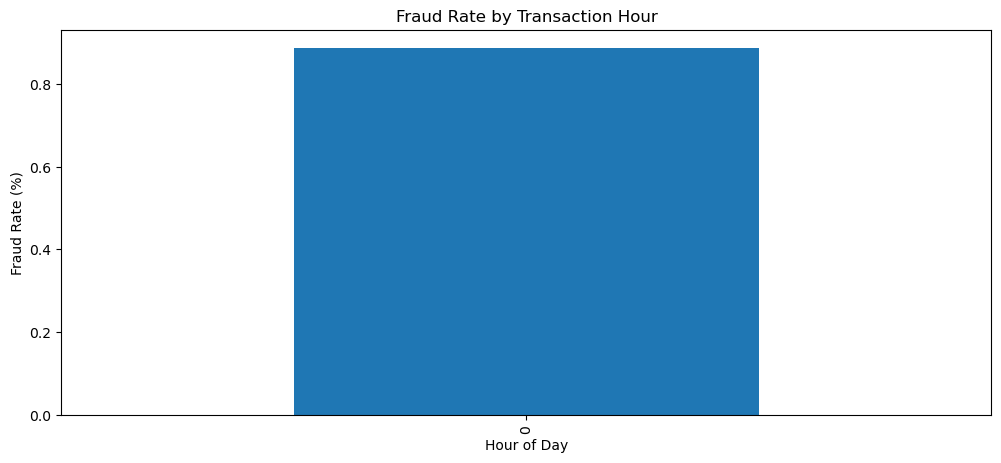

In [75]:
df["transaction_hour"] = df["transaction_date"].dt.hour

hourly_fraud = (
    df.groupby("transaction_hour")["is_fraud"]
      .mean()
      .mul(100)
)

hourly_fraud.plot(kind="bar", figsize=(12, 5))
plt.title("Fraud Rate by Transaction Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Rate (%)")
plt.show()

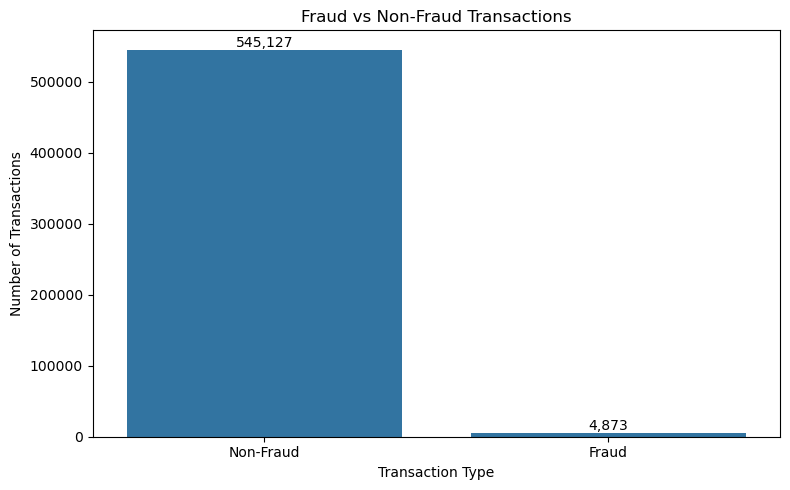

In [76]:
# Count fraud and non-fraud transactions
fraud_counts = df["is_fraud"].map({
    0: "Non-Fraud",
    1: "Fraud"
}).value_counts()

# Create bar chart
plt.figure(figsize=(8, 5))
sns.barplot(
    x=fraud_counts.index,
    y=fraud_counts.values
)

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

# Display count above each bar
for i, count in enumerate(fraud_counts.values):
    plt.text(i, count, f"{count:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()
